# 15 — K-Means e Agrupamento Hierárquico

> **Status:** notebook revisado e validado para estudo em JupyterLab.
>
> **Continuidade:** exemplos com dados sintéticos ou datasets integrados ao scikit-learn, sem acesso à internet.

**Objetivo geral:** construir compreensão conceitual e prática para aplicar este tema em problemas de Machine Learning, com avaliação adequada e interpretação dos resultados.


### Materiais complementares

- [Guia Técnico](./reference_materials/15_kmeans_hierarquico.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_kmeans_hierarquico.pdf)


## 1. Fundamentos, objetivos e contexto

**Objetivos.** Distinguir clustering de classificação, explicar centróides, inércia, dendrogramas, distância e ligação (*linkage*).

K-Means procura grupos compactos em torno de centróides e depende da escala, inicialização e escolha de k. Clustering hierárquico constrói estrutura de fusões, representada por dendrograma. Rótulos de clusters são arbitrários e não devem ser comparados diretamente a rótulos de classes sem correspondência apropriada.


## 2. Fundamentos matemáticos

Objetivo K-Means: $\min_{C_1,\ldots,C_k,\mu_1,\ldots,\mu_k}\sum_{j=1}^k\sum_{x_i\in C_j}\lVert x_i-\mu_j\rVert_2^2$. A inércia diminui ou não aumenta quando $k$ aumenta; isso não torna sempre desejável escolher $k$ máximo.

**Conexão com disciplinas anteriores:** revise os conceitos matemáticos e estatísticos correspondentes. Não repetimos integralmente os capítulos de Python, visualização e inferência estatística.


## 3. Experimento guiado: preparando a pergunta

**Antes do código**, identifique: (a) quais dados são de treino, (b) qual informação poderá entrar no modelo, (c) que métrica ou propriedade será observada, e (d) que conclusão não é permitida pelos resultados. Estes exemplos são didáticos, com semente fixa onde aplicável.


In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
X,_=make_blobs(n_samples=220,centers=3,cluster_std=.7,random_state=42)
X=StandardScaler().fit_transform(X)  # Exploratório, sem teste preditivo
for k in [2,3,4,5]:
    km=KMeans(n_clusters=k,n_init=10,random_state=42).fit(X)
    print('k',k,'inércia',round(km.inertia_,2),'silhouette',round(silhouette_score(X,km.labels_),3))

k 2 inércia 134.51 silhouette 0.709
k 3 inércia 6.85 silhouette 0.892
k 4 inércia 5.77 silhouette 0.725
k 5 inércia 4.74 silhouette 0.549


### Como interpretar

Os números são resultados específicos do experimento e da amostra, não garantias universais. Verifique o que mudou, qual método foi usado e qual é o cenário de aplicação. Compare com a teoria matemática e não confunda desempenho de treino, validação e teste.


## 4. Segundo experimento ou extensão controlada

Mude apenas uma condição principal (algoritmo, parâmetro ou tipo de dado), quando possível, e registre o efeito. Não ajuste decisões com base no teste final.


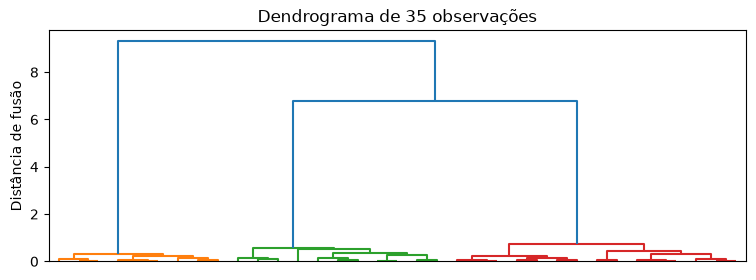

Silhouette aglomerativo: 0.892


In [2]:
from scipy.cluster.hierarchy import linkage,dendrogram
import matplotlib.pyplot as plt
Z=linkage(X[:35],method='ward')
fig,ax=plt.subplots(figsize=(9,3));dendrogram(Z,ax=ax,no_labels=True);ax.set_title('Dendrograma de 35 observações');ax.set_ylabel('Distância de fusão');plt.show()
ag=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X)
print('Silhouette aglomerativo:',round(silhouette_score(X,ag),3))

## 5. Exercício resolvido

**Enunciado:** reforce o conceito central com um exemplo menor, cujo resultado pode ser inspecionado diretamente.


In [3]:
# Exercício resolvido: centroide de três pontos
import numpy as np
pts=np.array([[0.,0.],[2.,2.],[4.,1.]])
print('Centróide:',pts.mean(axis=0),'inércia local:',round(float(((pts-pts.mean(axis=0))**2).sum()),3))

Centróide: [2. 1.] inércia local: 10.0


## 6. Interpretação, limitações e erros comuns

Silhouette favorece certa geometria de clusters e não garante valor substantivo. Variáveis irrelevantes e escala podem dominar. Hierarquia com método Ward assume distância euclidiana e costuma favorecer grupos aproximadamente compactos.

**Perguntas de revisão:**

1. Qual hipótese implícita sustenta o procedimento usado?
2. Que erro de implementação ou de validação poderia tornar o resultado artificialmente otimista?
3. Como você mudaria o experimento para refletir dados reais?


## 7. Consulta rápida

- `KMeans`: particional; `AgglomerativeClustering`: hierárquico.
- Inércia não seleciona automaticamente k ótimo.
- `silhouette_score`: qualidade interna, não prova de classes reais.
- Dendrograma mostra sequência de fusões.


## 8. Exercícios adicionais (para fazer no JupyterLab)

**Exercício A — sensibilidade:** altere um hiperparâmetro/hipótese e apresente uma tabela pequena com resultados e explicação. **Exercício B — revisão crítica:** construa um exemplo de uso incorreto (sem aplicá-lo a dados reais) e explique o procedimento correto. **Exercício C — comunicação:** escreva um parágrafo sobre escopo, métricas, suposições e limitações do método.

**Critério de aprovação:** códigos executam do começo ao fim, não há seleção pelo teste final e cada resultado possui interpretação.


## 9. Fontes e continuidade curricular

**Origem principal das aulas:** 15-agrupamento.pdf; Iris_KMeans.ipynb; Agrupamento_Hierárquico_(eurovision_vh).ipynb.

**Referências de atualização:** documentação de `scikit-learn` (<https://scikit-learn.org/stable/>); explicações matemáticas redigidas para esta reconstrução. Outros pacotes (Optuna, XGBoost, SHAP, imbalanced-learn) não são necessários para executar este capítulo.



## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** escolha de k. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **escolha de k** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **escolha de k** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.


In [4]:
# Evidência gráfica: agrupamento reproduzível usando dados sintéticos.
from pathlib import Path
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
X_plot, _ = make_blobs(n_samples=180, centers=3, cluster_std=0.75, random_state=42)
rotulos_plot = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_plot)
Path("outputs").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_plot[:, 0], X_plot[:, 1], c=rotulos_plot, s=18)
ax.set(title="K-Means — dados sintéticos", xlabel="Atributo 1", ylabel="Atributo 2")
fig.tight_layout()
fig.savefig("outputs/15_kmeans_sintetico.png", dpi=160)
plt.close(fig)
print("Gerado: outputs/15_kmeans_sintetico.png")

Gerado: outputs/15_kmeans_sintetico.png
